# PTM3D Exported Data Analysis

This notebook demonstrates loading simulation data exported by the PTM3D GUI
in both **GeoTIFF** and **HDF5** formats, visualizing spatial maps, and
extracting time series at specific geographic locations.

- **Sections 1-8**: GeoTIFF format (requires `rasterio`)
- **Sections 9-15**: HDF5 format (requires `h5py`)

**Requirements:** `numpy`, `matplotlib`, `rasterio` (GeoTIFF), `h5py` (HDF5)

In [2]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Add the ptm_geotiff module to the path
sys.path.insert(0, str(Path('..').resolve()))
from ptm_geotiff import read_geotiff, read_geotiff_folder, sample_points, get_coordinate_at_pixel

## 1. Configure paths

Set `export_dir` to the folder where PTM3D exported the GeoTIFF data.
For per-timestep exports, this folder will contain subfolders like
`temperature/`, `illumination/`, etc., each with `{field}_{NNNN}.tif` files.

In [3]:
# --- Edit this path to point to your PTM3D export directory ---
export_dir = Path("/Users/paha3326/Library/CloudStorage/OneDrive-UCB-O365/europa/heat3d/ptm/output/disco/exports/")

# List contents
if export_dir.exists():
    for p in sorted(export_dir.iterdir()):
        if p.is_dir():
            n = len(list(p.glob('*.tif')))
            print(f"  {p.name}/  ({n} GeoTIFF files)")
        else:
            print(f"  {p.name}  ({p.stat().st_size / 1024:.1f} KB)")
else:
    print(f"Directory not found: {export_dir}")
    print("Please update export_dir above.")

  .DS_Store  (6.0 KB)
  geotiff/  (0 GeoTIFF files)
  hdf5/  (0 GeoTIFF files)


## 2. Load temperature data

Use `read_geotiff_folder()` for per-timestep files, or `read_geotiff()`
for a single multi-band file.

In [5]:
# Load per-timestep GeoTIFFs from the temperature subdirectory
temp_dir = export_dir / "temperature"
data = read_geotiff_folder(temp_dir)

# Alternatively, for a single multi-band GeoTIFF:
# data = read_geotiff(export_dir / "temperature.tif")

print(f"Field:       {data['field']}")
print(f"Units:       {data['units']}")
print(f"Projection:  {data['projection']}")
print(f"Body radius: {data['body_radius'] / 1000:.1f} km")
print(f"Data shape:  {data['values'].shape}")
print(f"Timesteps:   {len(data['time_labels'])}")
if data['time_labels'][0]:
    print(f"First:       {data['time_labels'][0]}")
    print(f"Last:        {data['time_labels'][-1]}")
print(f"Lat shape:   {data['latitudes'].shape}")
print(f"Lon shape:   {data['longitudes'].shape}")
print(f"X shape:     {data['x'].shape}  (projected, metres)")
print(f"Y shape:     {data['y'].shape}  (projected, metres)")
print(f"X range:     {data['x'][0]/1000:.1f} to {data['x'][-1]/1000:.1f} km")
print(f"Y range:     {data['y'][0]/1000:.1f} to {data['y'][-1]/1000:.1f} km")

Field:       temperature
Units:       K
Projection:  stere
Body radius: 1737.4 km
Data shape:  (360, 664, 671)
Timesteps:   360
First:       2030-09-01T01:28:08.225
Last:        2030-11-28T14:09:35.803
Lat shape:   (664, 671)
Lon shape:   (664, 671)
X shape:     (671,)  (projected, metres)
Y shape:     (664,)  (projected, metres)
X range:     -10.3 to 10.0 km
Y range:     130.4 to 150.5 km


## 3. Plot a single timestep as a spatial map

/var/folders/tm/8041cn912wv15gzrzszx_mqw009n43/T/ipykernel_32040/3287138160.py:17: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  im = ax.pcolormesh(lons, lats, frame, shading='auto', cmap='magma')


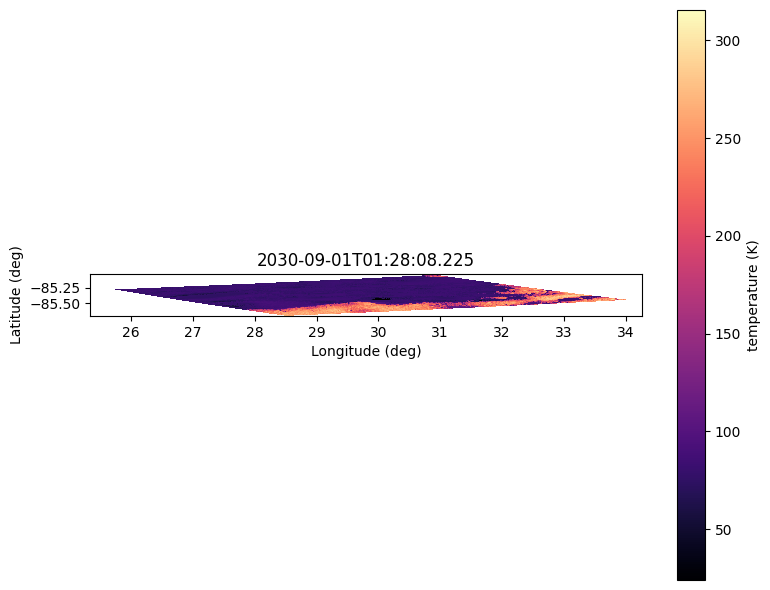

In [6]:
timestep = 0  # Index of the timestep to plot

fig, ax = plt.subplots(figsize=(8, 6))

vals = data['values']
frame = vals[timestep] if vals.ndim == 3 else vals
lats = data['latitudes']
lons = data['longitudes']

if lats.ndim == 1:
    # Equirectangular: regular lat/lon grid
    im = ax.pcolormesh(lons, lats, frame, shading='auto', cmap='magma')
    ax.set_xlabel('Longitude (deg)')
    ax.set_ylabel('Latitude (deg)')
else:
    # Stereographic: 2D coordinate arrays
    im = ax.pcolormesh(lons, lats, frame, shading='auto', cmap='magma')
    ax.set_xlabel('Longitude (deg)')
    ax.set_ylabel('Latitude (deg)')
    ax.set_aspect('equal')

cbar = fig.colorbar(im, ax=ax, label=f"{data['field']} ({data['units']})")
title = data['time_labels'][timestep] if data['time_labels'] else f'Timestep {timestep}'
ax.set_title(title)
plt.tight_layout()

## 4. Define sample points for time series

Pick a few geographic locations to extract temperature time series.
You can also define points by clicking on the map above and reading
off coordinates, or by choosing pixel indices directly.

In [7]:
# --- Define sample points as (latitude, longitude) ---
# Edit these to match locations within your simulation domain.
# You can also pick points from pixel coordinates:
#   lat, lon = get_coordinate_at_pixel(data, row=50, col=60)

lats = data['latitudes']
lons = data['longitudes']

if lats.ndim == 1:
    lat_mid = float(lats[len(lats) // 2])
    lon_mid = float(lons[len(lons) // 2])
    lat_range = float(lats[-1] - lats[0])
    lon_range = float(lons[-1] - lons[0])
else:
    valid = np.isfinite(lats)
    lat_mid = float(np.nanmean(lats[valid]))
    lon_mid = float(np.nanmean(lons[valid]))
    lat_range = float(np.nanmax(lats) - np.nanmin(lats))
    lon_range = float(np.nanmax(lons) - np.nanmin(lons))

# Pick a center point and several offset points
points = [
    (lat_mid, lon_mid),                                          # center
    (lat_mid + lat_range * 0.2, lon_mid),                        # north of center
    (lat_mid - lat_range * 0.2, lon_mid),                        # south of center
    (lat_mid, lon_mid + lon_range * 0.2),                        # east of center
]

labels = ['Center', 'North', 'South', 'East']

for label, (lat, lon) in zip(labels, points):
    print(f"{label:8s}: lat={lat:.4f}, lon={lon:.4f}")

Center  : lat=-85.3670, lon=29.8094
North   : lat=-85.2323, lon=29.8094
South   : lat=-85.5017, lon=29.8094
East    : lat=-85.3670, lon=31.5913


## 5. Extract and plot time series

In [8]:
ts = sample_points(data, points)  # shape: (n_points, n_timesteps)

print(f"Sampled {ts.shape[0]} points x {ts.shape[1]} timesteps")
for i, label in enumerate(labels):
    valid = np.isfinite(ts[i])
    if np.any(valid):
        print(f"  {label}: min={np.nanmin(ts[i]):.1f}, max={np.nanmax(ts[i]):.1f}, "
              f"mean={np.nanmean(ts[i]):.1f} {data['units']}")
    else:
        print(f"  {label}: all NaN (point outside mesh coverage)")

Sampled 4 points x 360 timesteps
  Center: min=75.7, max=251.8, mean=148.5 K
  North: min=76.4, max=261.3, mean=152.1 K
  South: min=74.1, max=255.7, mean=127.4 K
  East: min=82.5, max=302.4, mean=172.0 K


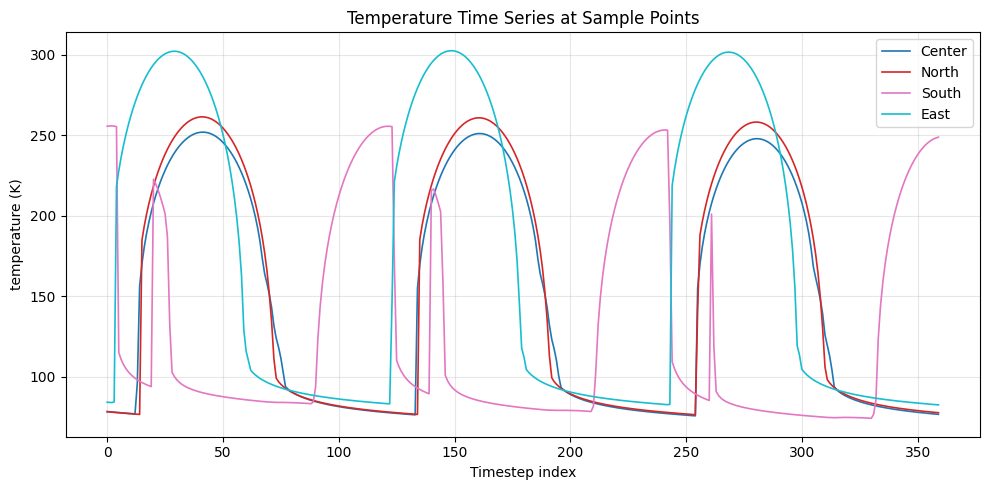

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))

n_timesteps = ts.shape[1]
x_axis = np.arange(n_timesteps)

colors = plt.cm.tab10(np.linspace(0, 1, len(labels)))
for i, (label, color) in enumerate(zip(labels, colors)):
    ax.plot(x_axis, ts[i], label=label, color=color, linewidth=1.2)

ax.set_xlabel('Timestep index')
ax.set_ylabel(f"{data['field']} ({data['units']})")
ax.set_title('Temperature Time Series at Sample Points')
ax.legend(loc='best')
ax.grid(True, alpha=0.3)
plt.tight_layout()

## 6. Map with sample points overlaid

Show where the sample points fall on the spatial map.

/var/folders/tm/8041cn912wv15gzrzszx_mqw009n43/T/ipykernel_32040/1220380949.py:9: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  im = ax.pcolormesh(data['longitudes'], data['latitudes'], frame,


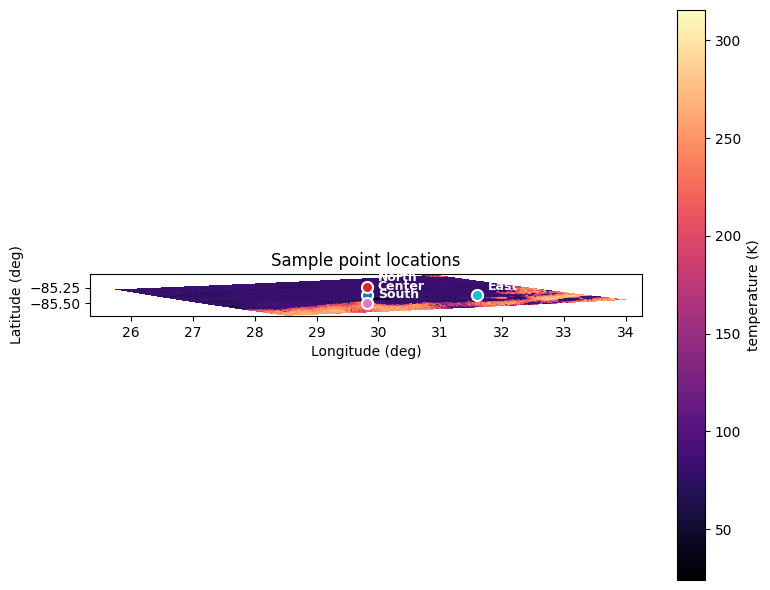

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))

frame = data['values'][0] if data['values'].ndim == 3 else data['values']

if data['latitudes'].ndim == 1:
    im = ax.pcolormesh(data['longitudes'], data['latitudes'], frame,
                       shading='auto', cmap='magma')
else:
    im = ax.pcolormesh(data['longitudes'], data['latitudes'], frame,
                       shading='auto', cmap='magma')
    ax.set_aspect('equal')

fig.colorbar(im, ax=ax, label=f"{data['field']} ({data['units']})")

# Overlay sample points
for i, (label, (lat, lon)) in enumerate(zip(labels, points)):
    ax.plot(lon, lat, 'o', color=colors[i], markersize=8,
            markeredgecolor='white', markeredgewidth=1.5)
    ax.annotate(label, (lon, lat), textcoords='offset points',
                xytext=(8, 4), fontsize=9, color='white',
                fontweight='bold')

ax.set_xlabel('Longitude (deg)')
ax.set_ylabel('Latitude (deg)')
ax.set_title('Sample point locations')
plt.tight_layout()

## 7. Diurnal temperature range map

Compute and display the per-pixel temperature range (max - min) across
all timesteps, showing which areas experience the largest diurnal variations.

/var/folders/tm/8041cn912wv15gzrzszx_mqw009n43/T/ipykernel_32040/2805324663.py:2: RuntimeWarning: All-NaN slice encountered
  t_min = np.nanmin(data['values'], axis=0)
/var/folders/tm/8041cn912wv15gzrzszx_mqw009n43/T/ipykernel_32040/2805324663.py:3: RuntimeWarning: All-NaN slice encountered
  t_max = np.nanmax(data['values'], axis=0)
/var/folders/tm/8041cn912wv15gzrzszx_mqw009n43/T/ipykernel_32040/2805324663.py:19: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  im = ax.pcolormesh(lons, lats, arr, shading='auto', cmap=cmap)


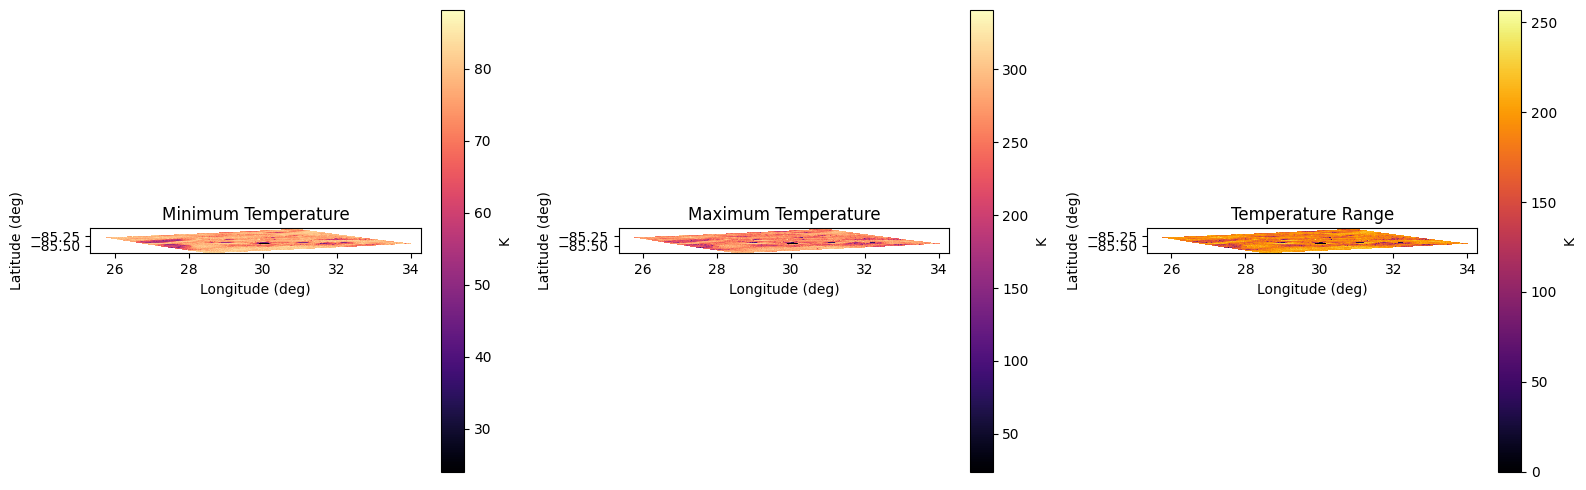

In [11]:
if data['values'].ndim == 3 and data['values'].shape[0] > 1:
    t_min = np.nanmin(data['values'], axis=0)
    t_max = np.nanmax(data['values'], axis=0)
    t_range = t_max - t_min

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    lats = data['latitudes']
    lons = data['longitudes']

    for ax, arr, title, cmap in zip(
        axes,
        [t_min, t_max, t_range],
        ['Minimum Temperature', 'Maximum Temperature', 'Temperature Range'],
        ['magma', 'magma', 'inferno']
    ):
        if lats.ndim == 1:
            im = ax.pcolormesh(lons, lats, arr, shading='auto', cmap=cmap)
        else:
            im = ax.pcolormesh(lons, lats, arr, shading='auto', cmap=cmap)
            ax.set_aspect('equal')
        fig.colorbar(im, ax=ax, label=f'{data["units"]}')
        ax.set_title(title)
        ax.set_xlabel('Longitude (deg)')
        ax.set_ylabel('Latitude (deg)')

    plt.tight_layout()
else:
    print("Single timestep -- skipping range map.")

## 8. Plot on projected (x, y) coordinates

For polar stereographic projections, plotting on the native projected
coordinate grid (in metres or km) gives a regular rectangular image
without the distortion that comes from mapping 2D lat/lon onto a
non-conformal axis. The `x` and `y` arrays from the reader are
1D arrays in ascending order, matching the data array dimensions.

/var/folders/tm/8041cn912wv15gzrzszx_mqw009n43/T/ipykernel_32040/1924192718.py:19: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  im0 = ax.pcolormesh(lons, lats, frame, shading='auto', cmap='magma')


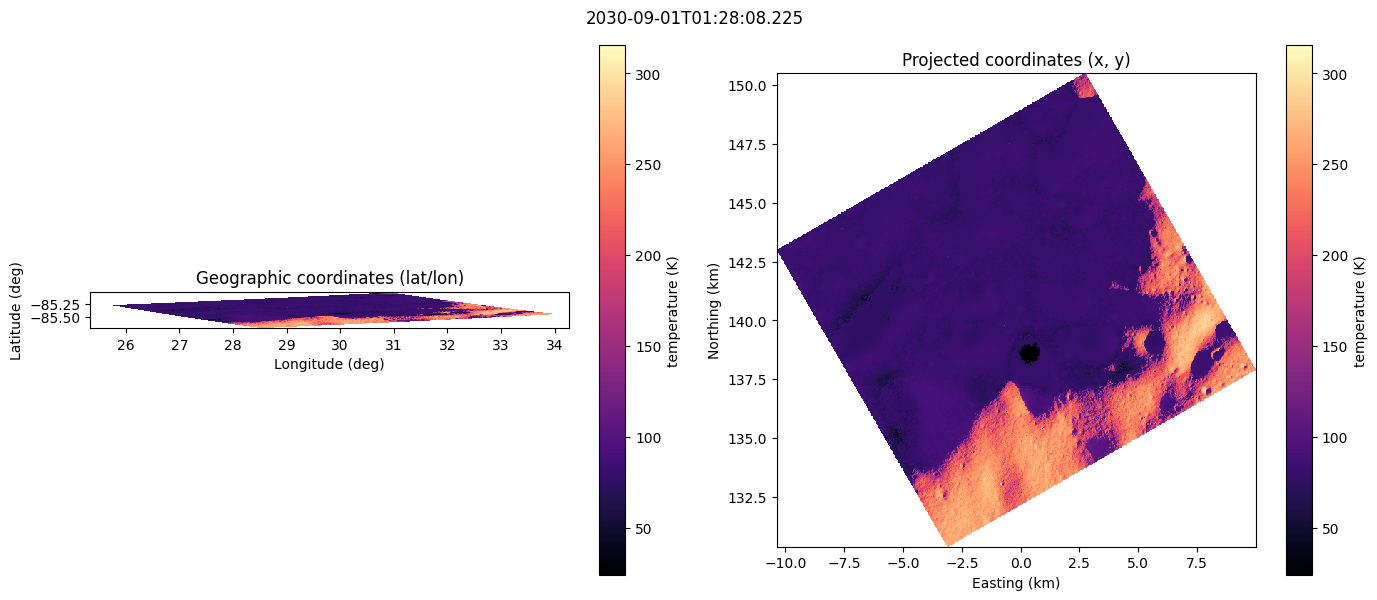

In [12]:
timestep = 0
frame = data['values'][timestep] if data['values'].ndim == 3 else data['values']

# Convert projected coordinates from metres to km for cleaner axis labels
x_km = data['x'] / 1000.0
y_km = data['y'] / 1000.0

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: geographic (lat/lon) coordinates
ax = axes[0]
lats = data['latitudes']
lons = data['longitudes']
if lats.ndim == 1:
    im0 = ax.pcolormesh(lons, lats, frame, shading='auto', cmap='magma')
    ax.set_xlabel('Longitude (deg)')
    ax.set_ylabel('Latitude (deg)')
else:
    im0 = ax.pcolormesh(lons, lats, frame, shading='auto', cmap='magma')
    ax.set_xlabel('Longitude (deg)')
    ax.set_ylabel('Latitude (deg)')
    ax.set_aspect('equal')
fig.colorbar(im0, ax=ax, label=f"{data['field']} ({data['units']})")
ax.set_title('Geographic coordinates (lat/lon)')

# Right: projected (x, y) coordinates
ax = axes[1]
im1 = ax.pcolormesh(x_km, y_km, frame, shading='auto', cmap='magma')
ax.set_xlabel('Easting (km)')
ax.set_ylabel('Northing (km)')
ax.set_aspect('equal')
fig.colorbar(im1, ax=ax, label=f"{data['field']} ({data['units']})")
ax.set_title('Projected coordinates (x, y)')

title = data['time_labels'][timestep] if data['time_labels'] else f'Timestep {timestep}'
fig.suptitle(title, fontsize=12)
plt.tight_layout()

---

# PTM3D HDF5 Data Analysis

The following cells demonstrate loading the same simulation data from the
HDF5 export format. The HDF5 file contains both the regridded data
(equivalent to the GeoTIFF export) and the original unstructured per-face
data, all in a single file.

**Requirements:** `h5py`, `numpy`, `matplotlib`

In [13]:
from ptm_hdf5 import (read_hdf5, read_hdf5_field, list_hdf5_fields,
                      sample_points as h5_sample_points)

## 9. Configure HDF5 path and list fields

Point `h5_path` to the `.h5` file in your export directory.
`list_hdf5_fields()` shows which fields are available in the file.

In [15]:
# --- Edit this path to point to your PTM3D HDF5 export file ---
h5_path = Path("/Users/paha3326/Library/CloudStorage/OneDrive-UCB-O365/europa/heat3d/ptm/output/disco/exports/ptm3d_data.h5")

if h5_path.exists():
    fields = list_hdf5_fields(h5_path)
    print("Available fields:")
    print(f"  Unstructured (per-face): {fields['unstructured']}")
    print(f"  Regridded (lat/lon grid): {fields['regridded']}")
    print(f"\nFile size: {h5_path.stat().st_size / (1024**2):.1f} MB")
else:
    print(f"File not found: {h5_path}")
    print("Please update h5_path above.")

Available fields:
  Unstructured (per-face): ['direct_solar', 'temperature']
  Regridded (lat/lon grid): ['direct_solar', 'temperature']

File size: 2256.0 MB


## 10. Load temperature from HDF5

`read_hdf5_field()` returns a dict with the same structure as the GeoTIFF
reader, making it easy to reuse the same plotting code.

In [16]:
h5data = read_hdf5_field(h5_path, "temperature")

print(f"Field:       {h5data['field']}")
print(f"Units:       {h5data['units']}")
print(f"Source:      {h5data['source']}")
print(f"Projection:  {h5data['projection']}")
print(f"Body radius: {h5data['body_radius'] / 1000:.1f} km")
print(f"Data shape:  {h5data['values'].shape}")
print(f"Timesteps:   {len(h5data['time_labels'])}")
if h5data['time_labels'] and h5data['time_labels'][0]:
    print(f"First:       {h5data['time_labels'][0]}")
    print(f"Last:        {h5data['time_labels'][-1]}")
if h5data['elapsed_seconds'].size > 0:
    dt_hours = (h5data['elapsed_seconds'][-1] - h5data['elapsed_seconds'][0]) / 3600
    print(f"Duration:    {dt_hours:.1f} hours")
print(f"Lat shape:   {h5data['latitudes'].shape}")
print(f"Lon shape:   {h5data['longitudes'].shape}")
if h5data['x'].size > 0:
    print(f"X range:     {h5data['x'][0]/1000:.1f} to {h5data['x'][-1]/1000:.1f} km")
    print(f"Y range:     {h5data['y'][0]/1000:.1f} to {h5data['y'][-1]/1000:.1f} km")

Field:       temperature
Units:       K
Source:      regridded
Projection:  stere
Body radius: 1737.4 km
Data shape:  (360, 664, 671)
Timesteps:   360
First:       2030-09-01T01:28:08.225
Last:        2030-11-28T14:09:35.803
Duration:    2124.7 hours
Lat shape:   (664, 671)
Lon shape:   (664, 671)
X range:     -10.3 to 10.0 km
Y range:     130.4 to 150.5 km


## 11. Plot a single timestep from HDF5

/var/folders/tm/8041cn912wv15gzrzszx_mqw009n43/T/ipykernel_32040/1994911665.py:15: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  im = ax.pcolormesh(lons, lats, frame, shading='auto', cmap='magma')


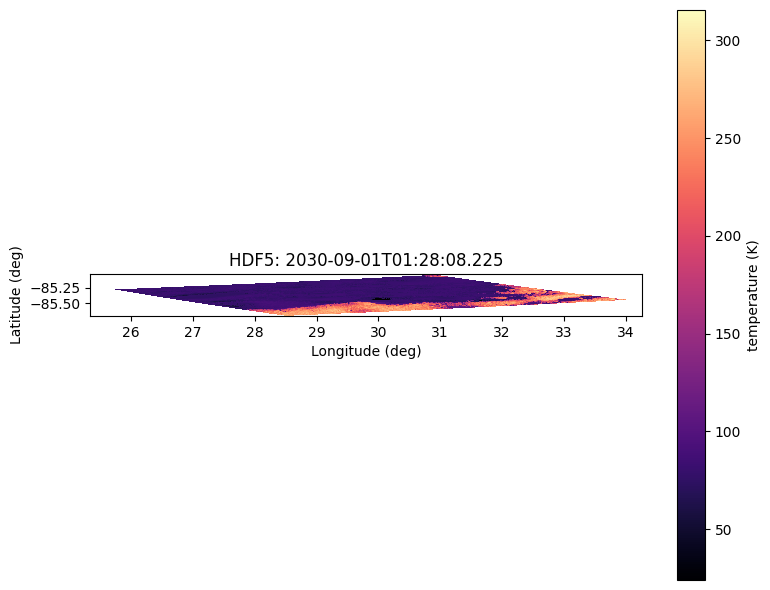

In [17]:
timestep = 0

fig, ax = plt.subplots(figsize=(8, 6))

vals = h5data['values']
frame = vals[timestep] if vals.ndim == 3 else vals
lats = h5data['latitudes']
lons = h5data['longitudes']

if lats.ndim == 1:
    im = ax.pcolormesh(lons, lats, frame, shading='auto', cmap='magma')
    ax.set_xlabel('Longitude (deg)')
    ax.set_ylabel('Latitude (deg)')
else:
    im = ax.pcolormesh(lons, lats, frame, shading='auto', cmap='magma')
    ax.set_xlabel('Longitude (deg)')
    ax.set_ylabel('Latitude (deg)')
    ax.set_aspect('equal')

fig.colorbar(im, ax=ax, label=f"{h5data['field']} ({h5data['units']})")
title = h5data['time_labels'][timestep] if h5data['time_labels'] else f'Timestep {timestep}'
ax.set_title(f"HDF5: {title}")
plt.tight_layout()

## 12. Sample points and time series from HDF5

Reuse the same sample points defined in Section 4.

In [18]:
h5_ts = h5_sample_points(h5data, points)  # shape: (n_points, n_timesteps)

print(f"Sampled {h5_ts.shape[0]} points x {h5_ts.shape[1]} timesteps")
for i, label in enumerate(labels):
    valid = np.isfinite(h5_ts[i])
    if np.any(valid):
        print(f"  {label}: min={np.nanmin(h5_ts[i]):.1f}, max={np.nanmax(h5_ts[i]):.1f}, "
              f"mean={np.nanmean(h5_ts[i]):.1f} {h5data['units']}")
    else:
        print(f"  {label}: all NaN (point outside mesh coverage)")

Sampled 4 points x 360 timesteps
  Center: min=75.7, max=251.8, mean=148.5 K
  North: min=76.4, max=261.3, mean=152.1 K
  South: min=74.1, max=255.7, mean=127.4 K
  East: min=82.5, max=302.4, mean=172.0 K


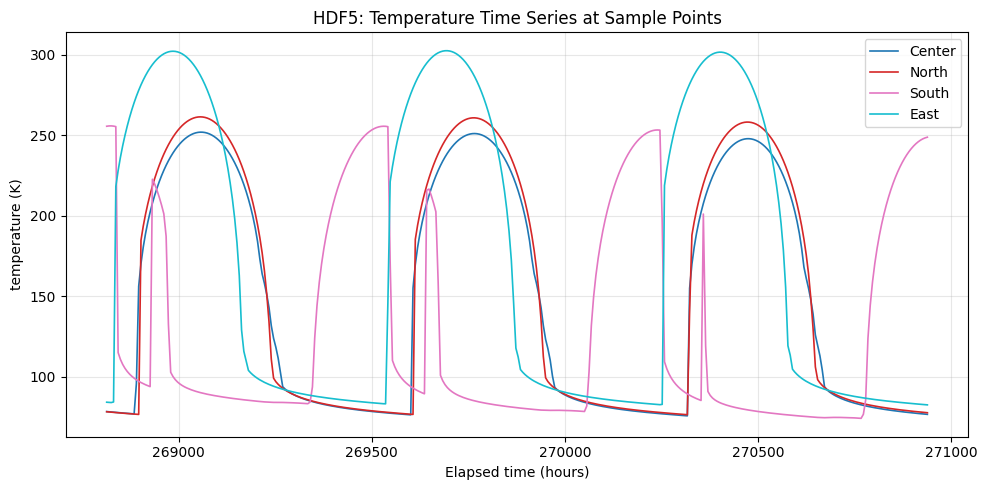

In [19]:
# Plot time series using elapsed time (hours) if available, otherwise timestep index
fig, ax = plt.subplots(figsize=(10, 5))

if h5data['elapsed_seconds'].size > 0:
    x_axis = h5data['elapsed_seconds'] / 3600.0  # hours
    ax.set_xlabel('Elapsed time (hours)')
else:
    x_axis = np.arange(h5_ts.shape[1])
    ax.set_xlabel('Timestep index')

colors = plt.cm.tab10(np.linspace(0, 1, len(labels)))
for i, (label, color) in enumerate(zip(labels, colors)):
    ax.plot(x_axis, h5_ts[i], label=label, color=color, linewidth=1.2)

ax.set_ylabel(f"{h5data['field']} ({h5data['units']})")
ax.set_title('HDF5: Temperature Time Series at Sample Points')
ax.legend(loc='best')
ax.grid(True, alpha=0.3)
plt.tight_layout()

## 13. Projected (x, y) plot from HDF5

Same side-by-side comparison of geographic vs. projected coordinates,
now loaded from the HDF5 file.

/var/folders/tm/8041cn912wv15gzrzszx_mqw009n43/T/ipykernel_32040/2501822780.py:15: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  im0 = ax.pcolormesh(lons, lats, frame, shading='auto', cmap='magma')


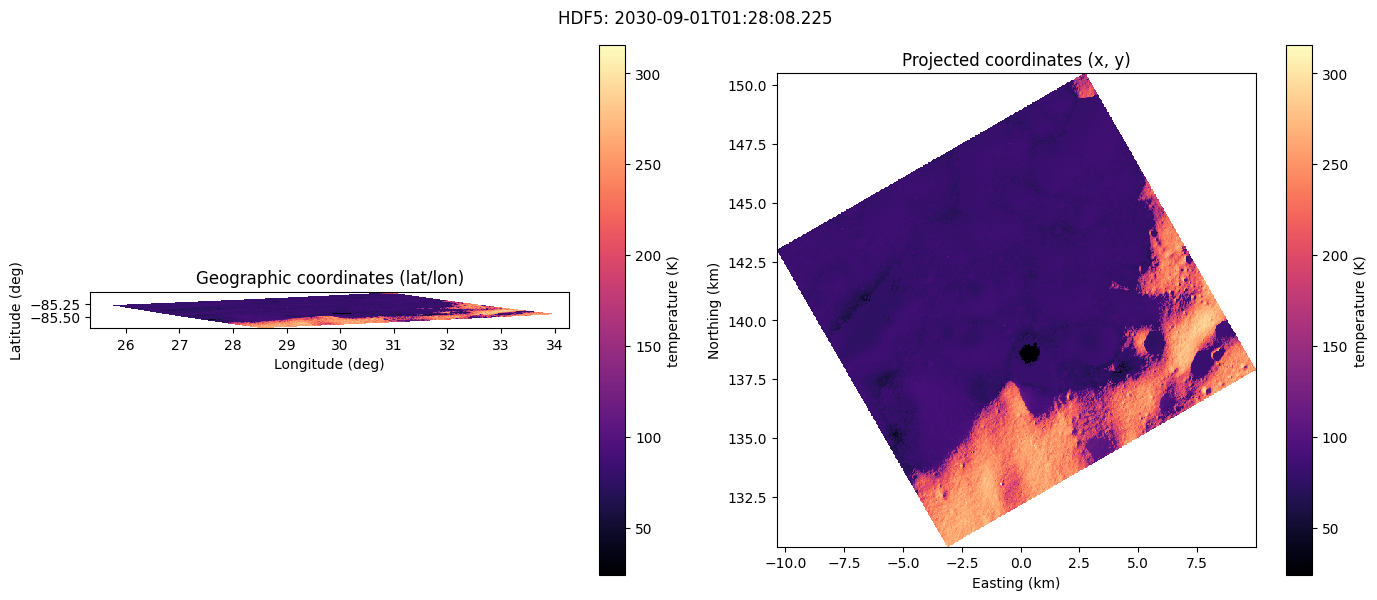

In [20]:
timestep = 0
frame = h5data['values'][timestep] if h5data['values'].ndim == 3 else h5data['values']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: geographic (lat/lon) coordinates
ax = axes[0]
lats = h5data['latitudes']
lons = h5data['longitudes']
if lats.ndim == 1:
    im0 = ax.pcolormesh(lons, lats, frame, shading='auto', cmap='magma')
    ax.set_xlabel('Longitude (deg)')
    ax.set_ylabel('Latitude (deg)')
else:
    im0 = ax.pcolormesh(lons, lats, frame, shading='auto', cmap='magma')
    ax.set_xlabel('Longitude (deg)')
    ax.set_ylabel('Latitude (deg)')
    ax.set_aspect('equal')
fig.colorbar(im0, ax=ax, label=f"{h5data['field']} ({h5data['units']})")
ax.set_title('Geographic coordinates (lat/lon)')

# Right: projected (x, y) coordinates
ax = axes[1]
if h5data['x'].size > 0 and h5data['y'].size > 0:
    x_km = h5data['x'] / 1000.0
    y_km = h5data['y'] / 1000.0
    im1 = ax.pcolormesh(x_km, y_km, frame, shading='auto', cmap='magma')
    ax.set_xlabel('Easting (km)')
    ax.set_ylabel('Northing (km)')
    ax.set_aspect('equal')
    fig.colorbar(im1, ax=ax, label=f"{h5data['field']} ({h5data['units']})")
    ax.set_title('Projected coordinates (x, y)')
else:
    ax.text(0.5, 0.5, 'No projected coordinates\n(equirectangular data)',
            ha='center', va='center', transform=ax.transAxes, fontsize=12)
    ax.set_title('Projected coordinates (not available)')

title = h5data['time_labels'][timestep] if h5data['time_labels'] else f'Timestep {timestep}'
fig.suptitle(f"HDF5: {title}", fontsize=12)
plt.tight_layout()

## 14. Diurnal temperature range from HDF5

/var/folders/tm/8041cn912wv15gzrzszx_mqw009n43/T/ipykernel_32040/2121136635.py:2: RuntimeWarning: All-NaN slice encountered
  t_min = np.nanmin(h5data['values'], axis=0)
/var/folders/tm/8041cn912wv15gzrzszx_mqw009n43/T/ipykernel_32040/2121136635.py:3: RuntimeWarning: All-NaN slice encountered
  t_max = np.nanmax(h5data['values'], axis=0)
/var/folders/tm/8041cn912wv15gzrzszx_mqw009n43/T/ipykernel_32040/2121136635.py:19: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  im = ax.pcolormesh(lons, lats, arr, shading='auto', cmap=cmap)


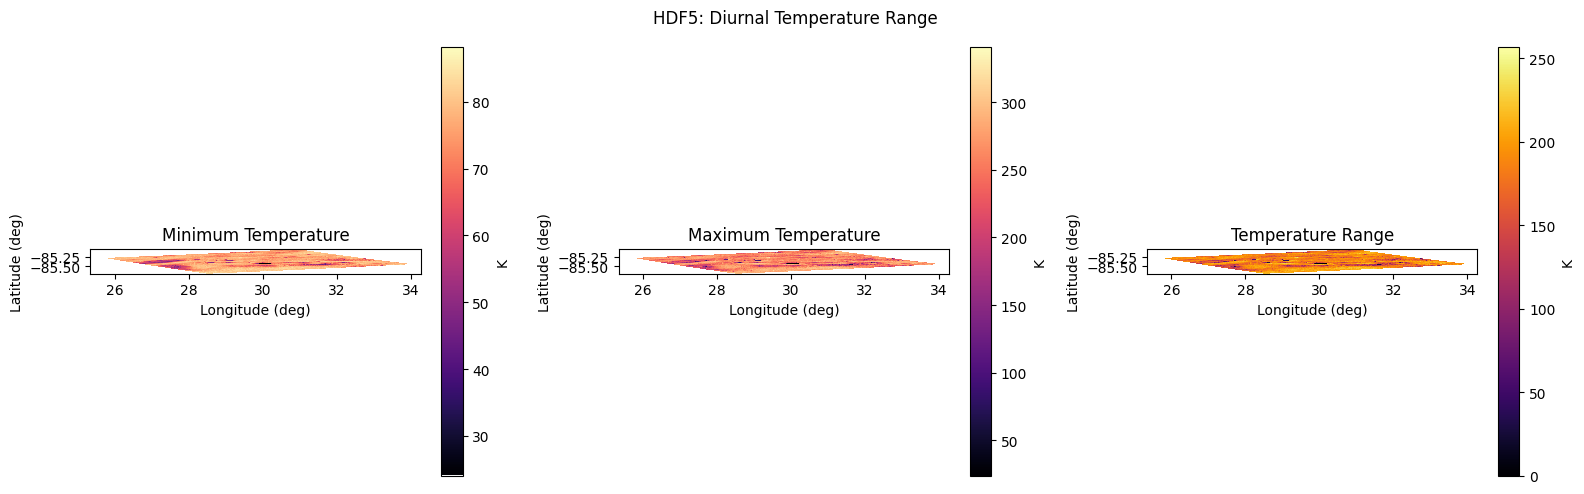

In [21]:
if h5data['values'].ndim == 3 and h5data['values'].shape[0] > 1:
    t_min = np.nanmin(h5data['values'], axis=0)
    t_max = np.nanmax(h5data['values'], axis=0)
    t_range = t_max - t_min

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    lats = h5data['latitudes']
    lons = h5data['longitudes']

    for ax, arr, title, cmap in zip(
        axes,
        [t_min, t_max, t_range],
        ['Minimum Temperature', 'Maximum Temperature', 'Temperature Range'],
        ['magma', 'magma', 'inferno']
    ):
        if lats.ndim == 1:
            im = ax.pcolormesh(lons, lats, arr, shading='auto', cmap=cmap)
        else:
            im = ax.pcolormesh(lons, lats, arr, shading='auto', cmap=cmap)
            ax.set_aspect('equal')
        fig.colorbar(im, ax=ax, label=f'{h5data["units"]}')
        ax.set_title(title)
        ax.set_xlabel('Longitude (deg)')
        ax.set_ylabel('Latitude (deg)')

    fig.suptitle('HDF5: Diurnal Temperature Range', fontsize=12)
    plt.tight_layout()
else:
    print("Single timestep -- skipping range map.")

## 15. Access full HDF5 contents (mesh + all fields)

`read_hdf5()` loads everything from the file: mesh geometry, all fields
(both unstructured per-face and regridded), and all metadata. This is
useful when you need access to the raw triangular mesh or want to compare
multiple fields.

In [22]:
full = read_hdf5(h5_path)

print("=== Mesh ===")
print(f"  Vertices: {full['mesh']['vertices'].shape}")
print(f"  Faces:    {full['mesh']['faces'].shape}")

print(f"\n=== Time ===")
print(f"  Timesteps:  {len(full['time_labels'])}")
if full['elapsed_seconds'].size > 0:
    print(f"  Duration:   {(full['elapsed_seconds'][-1] - full['elapsed_seconds'][0])/3600:.1f} hours")

print(f"\n=== Projection ===")
print(f"  Type:       {full['projection']}")
print(f"  Resolution: {full['resolution']} deg")
print(f"  Body R:     {full['body_radius']/1000:.1f} km")
if full['proj4']:
    print(f"  PROJ4:      {full['proj4']}")

print(f"\n=== Fields ===")
for name, fdata in full['fields'].items():
    regrid_shape = fdata['values'].shape if fdata['values'] is not None else None
    face_shape = fdata['face_values'].shape if fdata['face_values'] is not None else None
    print(f"  {name}:")
    print(f"    Units:        {fdata['units']}")
    print(f"    Description:  {fdata['description']}")
    print(f"    Regridded:    {regrid_shape}")
    print(f"    Unstructured: {face_shape}")

=== Mesh ===
  Vertices: (547404, 3)
  Faces:    (1091850, 3)

=== Time ===
  Timesteps:  360
  Duration:   2124.7 hours

=== Projection ===
  Type:       stere
  Resolution: 0.001 deg
  Body R:     1737.4 km
  PROJ4:      +proj=stere +lat_0=-90.0 +lat_ts=-90.0 +lon_0=29.88358974456787 +R=1737400.0 +units=m +no_defs

=== Fields ===
  direct_solar:
    Units:        W/m²
    Description:  Direct Solar
    Regridded:    (360, 664, 671)
    Unstructured: (360, 1091850)
  temperature:
    Units:        K
    Description:  Temperature
    Regridded:    (360, 664, 671)
    Unstructured: (360, 1091850)
